# 06 · Experiment E1: which input channels? (task T22, runs R01 to R09)

**RQ1.** Does extra radar information help? Three inputs are compared, everything else being the frozen default (MobileNetV2 encoder, BCE + Dice loss):

| Config | Input channels | Runs |
|---|---|---|
| VH only | VH | R04, R05, R06 |
| VV+VH | VV, VH | R07, R08, R09 |
| Default | VV, VH and the ratio VV − VH | R01, R02, R03 |

Three seeds per config show how much a result moves by chance alone. A difference is only claimed when it is larger than that.

The training defaults were frozen and tagged in git (`defaults-frozen`, task T19) **before** this notebook was first run. The first cell checks that the code still matches that tag.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis, viz
from src.config import STUDIES, load_config, run_table, runs_of
from src.runner import check_frozen, run_benchmark, run_evaluation, run_many

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("training and scoring code is identical to the frozen tag 'defaults-frozen' (commit %s)" % check_frozen()[:7])

STUDY = "E1"
CONFIGS = STUDIES[STUDY]["configs"]
pd.DataFrame([r for r in run_table() if r["config_name"] in CONFIGS]).fillna({"channels": "vv_vh_ratio"}).set_index("run_id")

training and scoring code is identical to the frozen tag 'defaults-frozen' (commit 43821af)


,config_name,study,seed,channels
run_id,,,,
R01,Default,"E1, E2, E3 (shared)",0,vv_vh_ratio
R02,Default,"E1, E2, E3 (shared)",1,vv_vh_ratio
R03,Default,"E1, E2, E3 (shared)",2,vv_vh_ratio
R04,VH only,E1,0,vh
R05,VH only,E1,1,vh
R06,VH only,E1,2,vh
R07,VV+VH,E1,0,vv_vh
R08,VV+VH,E1,1,vv_vh
R09,VV+VH,E1,2,vv_vh


## 1. R01 on test and Bolivia: scored once, now that the defaults are frozen

R01 was trained and inspected on validation data in notebook 05. Its test and Bolivia scores were deliberately not computed until the method was fixed.

In [2]:
_ = run_evaluation("R01")

[R01 was scored on test and Bolivia on 2026-11-11 13:12 UTC; not scoring it again]
R01 test     IoU 0.6681  P 0.8520  R 0.7558  F1 0.8010  mean per-chip IoU 0.3859 (87 chips)
R01 bolivia  IoU 0.6547  P 0.8890  R 0.7130  F1 0.7913  mean per-chip IoU 0.3808 (15 chips)


## 2. Train and score R02 to R09

Each run trains in its own process, then is scored once on test and Bolivia. Finished runs are not repeated when the notebook is run again; their saved logs are shown.

In [3]:
results = run_many(["R02", "R03", "R04", "R05", "R06", "R07", "R08", "R09"])


[R02 was trained on 2026-11-11 13:12 UTC; this is its saved log]
R02: Default | encoder mobilenetv2 | channels vv_vh_ratio | loss bce_dice | seed 1 | 5,419,473 parameters | mixed_float16
epoch  1/60 | loss 0.9121  iou 0.4138 | val_loss 1.3395  val_iou 0.0000 | lr 1.0e-03 |  53.3s *
epoch  2/60 | loss 0.7553  iou 0.4610 | val_loss 1.2584  val_iou 0.0008 | lr 1.0e-03 |   8.4s *
epoch  3/60 | loss 0.6862  iou 0.4821 | val_loss 0.8985  val_iou 0.2634 | lr 1.0e-03 |   8.3s *
epoch  4/60 | loss 0.6827  iou 0.4683 | val_loss 0.5898  val_iou 0.5631 | lr 1.0e-03 |   8.3s *
epoch  5/60 | loss 0.6829  iou 0.4716 | val_loss 0.7390  val_iou 0.5160 | lr 1.0e-03 |   8.4s
epoch  6/60 | loss 0.6515  iou 0.4986 | val_loss 0.4522  val_iou 0.6150 | lr 1.0e-03 |   8.2s *
epoch  7/60 | loss 0.6979  iou 0.4652 | val_loss 0.4603  val_iou 0.6107 | lr 1.0e-03 |   8.3s
epoch  8/60 | loss 0.6386  iou 0.5066 | val_loss 0.5444  val_iou 0.5541 | lr 1.0e-03 |   8.2s
epoch  9/60 | loss 0.6454  iou 0.5053 | val_loss 0

[R07 was trained on 2026-11-11 13:52 UTC; this is its saved log]
R07: VV+VH | encoder mobilenetv2 | channels vv_vh | loss bce_dice | seed 0 | 5,419,185 parameters | mixed_float16


epoch  1/60 | loss 1.0618  iou 0.3851 | val_loss 1.9368  val_iou 0.1135 | lr 1.0e-03 | 178.2s *
epoch  2/60 | loss 0.8549  iou 0.4450 | val_loss 0.8034  val_iou 0.4639 | lr 1.0e-03 |   8.2s *
epoch  3/60 | loss 0.7357  iou 0.4812 | val_loss 0.7383  val_iou 0.4734 | lr 1.0e-03 |   8.0s *
epoch  4/60 | loss 0.6726  iou 0.5118 | val_loss 0.5263  val_iou 0.5881 | lr 1.0e-03 |   8.0s *
epoch  5/60 | loss 0.6688  iou 0.4860 | val_loss 0.5316  val_iou 0.5779 | lr 1.0e-03 |   8.0s
epoch  6/60 | loss 0.6420  iou 0.5074 | val_loss 0.5140  val_iou 0.5826 | lr 1.0e-03 |   7.8s
epoch  7/60 | loss 0.6532  iou 0.5018 | val_loss 0.5938  val_iou 0.5428 | lr 1.0e-03 |   7.9s
epoch  8/60 | loss 0.6147  iou 0.5375 | val_loss 0.4306  val_iou 0.6301 | lr 1.0e-03 |   7.9s *
epoch  9/60 | loss 0.6227  iou 0.5254 | val_loss 0.6607  val_iou 0.4742 | lr 1.0e-03 |   8.0s
epoch 10/60 | loss 0.6359  iou 0.5264 | val_loss 0.4805  val_iou 0.6007 | lr 1.0e-03 |   8.0s
epoch 11/60 | loss 0.6006  iou 0.5565 | val_loss 0

[R08 was trained on 2026-11-11 14:02 UTC; this is its saved log]
R08: VV+VH | encoder mobilenetv2 | channels vv_vh | loss bce_dice | seed 1 | 5,419,185 parameters | mixed_float16
epoch  1/60 | loss 0.8934  iou 0.4212 | val_loss 1.0674  val_iou 0.0523 | lr 1.0e-03 |  50.8s *
epoch  2/60 | loss 0.7532  iou 0.4571 | val_loss 0.6760  val_iou 0.4850 | lr 1.0e-03 |   8.0s *
epoch  3/60 | loss 0.6924  iou 0.4765 | val_loss 0.5731  val_iou 0.5493 | lr 1.0e-03 |   8.0s *
epoch  4/60 | loss 0.6834  iou 0.4731 | val_loss 0.5893  val_iou 0.5715 | lr 1.0e-03 |   7.9s *
epoch  5/60 | loss 0.6888  iou 0.4720 | val_loss 0.5656  val_iou 0.5662 | lr 1.0e-03 |   8.0s
epoch  6/60 | loss 0.6530  iou 0.5000 | val_loss 0.5194  val_iou 0.5910 | lr 1.0e-03 |   7.8s *
epoch  7/60 | loss 0.6937  iou 0.4773 | val_loss 0.5665  val_iou 0.5438 | lr 1.0e-03 |   8.3s
epoch  8/60 | loss 0.6407  iou 0.5036 | val_loss 0.4923  val_iou 0.5903 | lr 1.0e-03 |   7.9s
epoch  9/60 | loss 0.6287  iou 0.5328 | val_loss 0.4544  va

## 3. Results

One row per run. Validation IoU is the score the checkpoint was chosen by; test and Bolivia were scored once, after training.

In [4]:
runs = analysis.runs_table()
study_runs = runs[runs["Config"].isin(CONFIGS)]
study_runs[["Run ID", "Config", "Seed", "Status", "Epochs trained", "Best epoch", "Val IoU (best)", "Test IoU",
            "Test precision", "Test recall", "Bolivia IoU", "Sec per epoch"]].set_index("Run ID")

,Config,Seed,Status,Epochs trained,Best epoch,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU,Sec per epoch
Run ID,,,,,,,,,,,
R01,Default,0,Finished,39.0000,24.0000,0.6282,0.6681,0.8520,0.7558,0.6547,8.6400
R02,Default,1,Finished,32.0000,17.0000,0.6449,0.6640,0.8437,0.7571,0.6213,8.4400
R03,Default,2,Finished,34.0000,19.0000,0.6435,0.6674,0.8135,0.7880,0.6347,8.5900
R04,VH only,0,Finished,39.0000,24.0000,0.6054,0.6392,0.8459,0.7235,0.6299,8.3000
R05,VH only,1,Finished,44.0000,29.0000,0.6110,0.6265,0.8161,0.7295,0.6027,8.3300
R06,VH only,2,Finished,47.0000,32.0000,0.6205,0.6377,0.8261,0.7366,0.6370,8.1600
R07,VV+VH,0,Finished,47.0000,32.0000,0.6442,0.6682,0.8511,0.7567,0.5885,8.2200
R08,VV+VH,1,Finished,54.0000,39.0000,0.6455,0.6776,0.8438,0.7748,0.6583,8.2300
R09,VV+VH,2,Finished,60.0000,45.0000,0.6613,0.6651,0.8685,0.7396,0.6499,8.2600


Mean ± standard deviation over the three seeds (the two threshold baselines, single deterministic runs, are shown for reference):

In [5]:
analysis.study_table(STUDY, analysis.summary_table(runs))

,Finished runs,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU
Config,,,,,,
Otsu (E0),1,0.388,0.433,0.483,0.809,0.653
Tuned VH threshold,1,0.492,0.524,0.747,0.637,0.531
VH only,3,0.612 ± 0.008,0.634 ± 0.007,0.829 ± 0.015,0.730 ± 0.007,0.623 ± 0.018
VV+VH,3,0.650 ± 0.009,0.670 ± 0.006,0.854 ± 0.013,0.757 ± 0.018,0.632 ± 0.038
Default,3,0.639 ± 0.009,0.667 ± 0.002,0.836 ± 0.020,0.767 ± 0.018,0.637 ± 0.017


**Is a difference real?** The project's rule: a gap between two configs counts only if it is larger than the seed-to-seed standard deviation.

In [6]:
gaps = analysis.gap_table(STUDY, runs)
gaps.to_csv(ROOT / "results" / f"{STUDY}_gaps.csv", index=False)
gaps.set_index(["Metric", "A", "B"])

,,,Mean A,Mean B,Gap (A - B),Larger std,Gap / std,Gap larger than std,Welch p
Metric,A,B,,,,,,,
Test IoU,VH only,VV+VH,0.6345,0.6703,-0.0358,0.0069,5.1693,True,0.0029
Bolivia IoU,VH only,VV+VH,0.6232,0.6322,-0.0091,0.0381,0.2377,False,0.7358
Test IoU,VH only,Default,0.6345,0.6665,-0.0320,0.0069,4.6234,True,0.0098
Bolivia IoU,VH only,Default,0.6232,0.6369,-0.0137,0.0181,0.7573,False,0.3914
Test IoU,VV+VH,Default,0.6703,0.6665,0.0038,0.0065,0.5832,False,0.4232
Bolivia IoU,VV+VH,Default,0.6322,0.6369,-0.0047,0.0381,0.1221,False,0.8600


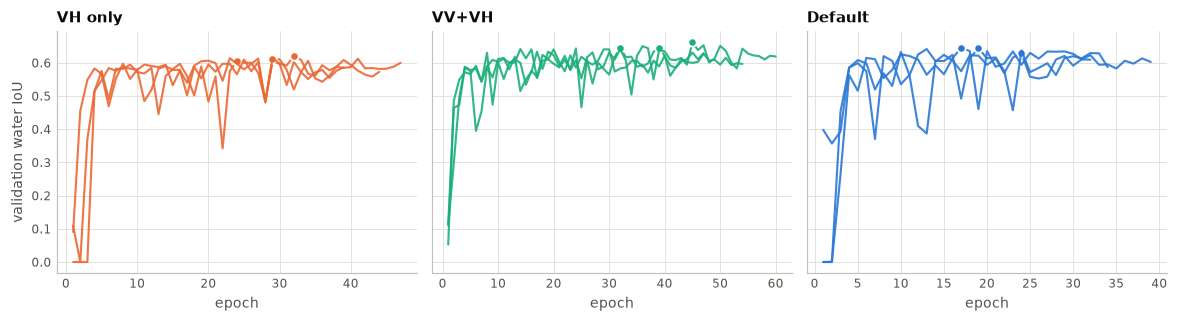

In [7]:
hist = {c: analysis.histories(runs_of(c)) for c in CONFIGS}
axes = viz.plot_val_curves(hist)
axes[0].figure.tight_layout()
viz.savefig(axes[0].figure, ROOT / "figures" / f"{STUDY}_val_curves.png")
plt.show()

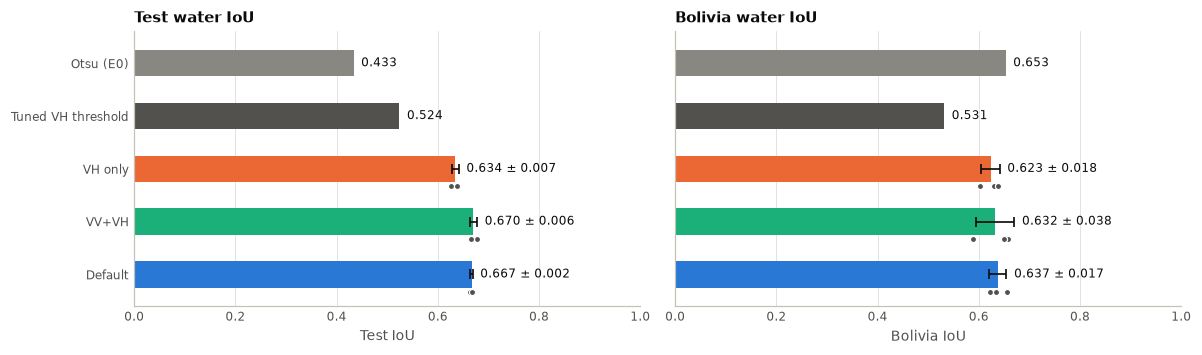

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
done = runs[runs["Status"] == "Finished"]
for ax, metric in zip(axes, ("Test IoU", "Bolivia IoU")):
    viz.plot_config_bars(done, CONFIGS, metric, ax, baseline=("Otsu (E0)", "Tuned VH threshold"))
    ax.set_title(metric.replace("IoU", "water IoU"))
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / f"{STUDY}_bars.png")
plt.show()

## 4. Reading (RQ1)

* **Adding VV to VH is a real gain on the test chips.** VH alone reaches 0.634 ± 0.007, VV+VH 0.670 ± 0.006: a gap of 0.036, five times the spread between seeds. Precision and recall both rise (0.829 → 0.854 and 0.730 → 0.757), so the second polarisation removes false alarms and finds more water at the same time.
* **The ratio channel adds nothing.** VV+VH+ratio (the default) scores 0.667 ± 0.002, VV+VH 0.670 ± 0.006; the gap of 0.004 is smaller than the spread between seeds. In hindsight this is no surprise: the ratio is VV − VH, a fixed linear combination of the two inputs, which the first convolution can form by itself.
* **On Bolivia no input is better than another.** 0.623 ± 0.018, 0.632 ± 0.038 and 0.637 ± 0.017: every gap is well inside the noise, and the noise on the 15 Bolivia chips is three to six times larger than on the 90 test chips.
* **Against the thresholds.** On the test chips every U-Net is far above both threshold rules (0.433 and 0.524). On Bolivia none is clearly above Otsu's 0.653. Notebook 09 quantifies this and notebook 10 looks for the reason.
* The runs with two input channels trained longest (47 to 60 epochs, against 32 to 39 for the default).